# Лабораторна робота № 2

## Оптимізаційна задача та аналіз чутливості

**Дисципліна:** Інтелектуальний аналіз та візуалізація даних (СК26)
**Тривалість:** 2 год аудиторно + 3 год самостійної роботи · **Максимальна оцінка:** 4 бали

---

### Мета роботи

Побудувати оптимізаційну модель у двох середовищах, прочитати звіт про стійкість
і **ухвалити на його основі господарське рішення**.

Розв'язати задачу — не мета. Solver зробить це за дві секунди. Робота оцінюється за
те, що ви зумієте зі звіту витягнути.

### Дві частини

| Частина | Задача | Де виконується |
|---|---|---|
| **1** | виробнича задача — Excel і Python | аудиторно |
| **2** | транспортна задача — Python | самостійно |

Друга частина потрібна не для повторення. Там та сама методика поводиться інакше,
і ви маєте побачити, де саме проходить межа її застосовності.

### Що здається

1. Цей файл `.ipynb` із заповненими розв'язками. **Виконується згори донизу на чистому
   ядрі** (Kernel → Restart & Run All) без помилок — перевіряється першою дією на захисті.
2. Файл Excel з моделлю, налаштуваннями Solver і **звітом про стійкість** окремим аркушем.
3. Заповнена декларація про використання ШІ (етап 12).

### Оцінювання

| Бали | Що досягнуто |
|---|---|
| 0 | Модель не сформульовано або розв'язок не отримано |
| 1 | Розв'язок отримано лише в одному середовищі, звіт про стійкість не проаналізовано |
| 2 | Задачу розв'язано в обох середовищах і звіти зіставлено, але тіньові ціни та діапазони не інтерпретовано |
| 4 | Звіт прочитано й перевірено експериментом, ухвалено обґрунтоване рішення про закупівлю, виконано частину 2 з поясненням розбіжності |

---
## Крок 0. Ваші дані та варіант

In [102]:
ПІБ = 'Бобринок Ангеліна Вадимівна'
ГРУПА = 'ШІ-32'
ВАРІАНТ = 3     # ваш номер за списком групи

assert ПІБ and ГРУПА and 1 <= ВАРІАНТ <= 30, 'Заповніть ПІБ, ГРУПУ та ВАРІАНТ (1..30)'

In [103]:
# --- клітинку не редагувати: вона видає дані вашого варіанта -----------------
import json, numpy as np, pandas as pd

ДАНІ_ВАРІАНТІВ = json.loads('''{"1": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[0, 2, 1, 1], [3, 3, 0, 6], [2, 3, 0, 2], [4, 6, 0, 5], [3, 1, 5, 4]], "c": [21, 69, 44, 39], "b": [929, 410, 507, 865, 425], "ресурс_пропозиції": 1, "ціна_пропозиції": 16.2, "обсяг_пропозиції": 44}, "2": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 2, 5, 2], [6, 5, 4, 2], [5, 2, 0, 3], [2, 1, 5, 0], [5, 5, 6, 2]], "c": [40, 66, 24, 34], "b": [1271, 702, 915, 1388, 804], "ресурс_пропозиції": 1, "ціна_пропозиції": 16.7, "обсяг_пропозиції": 204}, "3": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[5, 2, 6, 6], [3, 4, 3, 6], [1, 6, 6, 0], [3, 1, 6, 1], [4, 1, 1, 4]], "c": [51, 16, 34, 22], "b": [1189, 686, 1311, 512, 1030], "ресурс_пропозиції": 3, "ціна_пропозиції": 11.3, "обсяг_пропозиції": 348}, "4": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[5, 0, 0, 0], [1, 0, 5, 2], [2, 4, 6, 5], [3, 0, 5, 3], [2, 1, 2, 5]], "c": [41, 50, 54, 26], "b": [815, 344, 840, 840, 382], "ресурс_пропозиції": 4, "ціна_пропозиції": 8.3, "обсяг_пропозиції": 144}, "5": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[3, 0, 6, 6], [3, 2, 2, 4], [5, 5, 0, 6], [2, 1, 5, 3], [5, 5, 4, 2]], "c": [32, 66, 25, 24], "b": [874, 1034, 1349, 845, 1394], "ресурс_пропозиції": 2, "ціна_пропозиції": 8.6, "обсяг_пропозиції": 90}, "6": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[3, 2, 1, 4], [4, 2, 2, 1], [3, 5, 1, 2], [3, 2, 0, 2], [6, 4, 6, 3]], "c": [40, 62, 19, 57], "b": [630, 391, 1349, 811, 1085], "ресурс_пропозиції": 1, "ціна_пропозиції": 29.5, "обсяг_пропозиції": 268}, "7": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[0, 0, 5, 5], [4, 4, 0, 1], [2, 4, 0, 6], [6, 3, 4, 1], [2, 2, 1, 0]], "c": [20, 59, 63, 41], "b": [1189, 1189, 1217, 915, 424], "ресурс_пропозиції": 3, "ціна_пропозиції": 8.0, "обсяг_пропозиції": 314}, "8": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[2, 1, 3, 5], [3, 1, 0, 6], [1, 6, 1, 5], [2, 2, 4, 0], [6, 1, 2, 2]], "c": [60, 25, 59, 25], "b": [1279, 761, 376, 1230, 1065], "ресурс_пропозиції": 3, "ціна_пропозиції": 9.5, "обсяг_пропозиції": 234}, "9": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[5, 2, 1, 2], [5, 0, 1, 3], [5, 4, 6, 4], [4, 1, 1, 5], [6, 0, 3, 0]], "c": [58, 39, 54, 16], "b": [1147, 1199, 1280, 404, 1170], "ресурс_пропозиції": 2, "ціна_пропозиції": 6.1, "обсяг_пропозиції": 672}, "10": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 0, 4, 3], [0, 6, 0, 6], [5, 5, 3, 5], [6, 2, 3, 3], [3, 0, 0, 4]], "c": [20, 29, 37, 63], "b": [905, 344, 866, 1390, 355], "ресурс_пропозиції": 0, "ціна_пропозиції": 5.3, "обсяг_пропозиції": 78}, "11": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[2, 1, 0, 3], [3, 1, 4, 0], [1, 0, 3, 2], [3, 2, 2, 6], [3, 6, 0, 3]], "c": [30, 16, 51, 35], "b": [1312, 838, 1062, 1038, 1236], "ресурс_пропозиції": 1, "ціна_пропозиції": 15.6, "обсяг_пропозиції": 778}, "12": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[5, 2, 0, 5], [1, 1, 3, 6], [6, 3, 5, 4], [2, 4, 6, 0], [4, 6, 2, 4]], "c": [39, 55, 36, 26], "b": [788, 661, 458, 1005, 535], "ресурс_пропозиції": 4, "ціна_пропозиції": 5.0, "обсяг_пропозиції": 762}, "13": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[1, 5, 3, 0], [6, 4, 6, 3], [4, 4, 4, 1], [0, 3, 5, 3], [3, 5, 3, 3]], "c": [59, 42, 53, 19], "b": [937, 1390, 603, 1120, 1334], "ресурс_пропозиції": 2, "ціна_пропозиції": 15.1, "обсяг_пропозиції": 646}, "14": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 3, 3, 4], [6, 6, 1, 6], [1, 3, 5, 1], [1, 5, 1, 4], [4, 4, 0, 3]], "c": [26, 56, 41, 40], "b": [969, 672, 1364, 878, 618], "ресурс_пропозиції": 2, "ціна_пропозиції": 5.0, "обсяг_пропозиції": 222}, "15": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[5, 3, 3, 1], [2, 5, 6, 6], [3, 1, 0, 0], [0, 4, 4, 6], [2, 2, 2, 6]], "c": [64, 58, 34, 63], "b": [613, 316, 1035, 739, 810], "ресурс_пропозиції": 0, "ціна_пропозиції": 5.4, "обсяг_пропозиції": 354}, "16": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[1, 6, 4, 2], [4, 1, 1, 2], [4, 4, 6, 6], [5, 6, 3, 3], [1, 2, 4, 2]], "c": [33, 40, 58, 17], "b": [412, 1005, 996, 599, 390], "ресурс_пропозиції": 4, "ціна_пропозиції": 8.2, "обсяг_пропозиції": 44}, "17": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[2, 6, 0, 3], [2, 5, 5, 3], [6, 0, 4, 5], [1, 3, 6, 2], [0, 1, 4, 4]], "c": [33, 52, 20, 66], "b": [989, 1079, 873, 1327, 1224], "ресурс_пропозиції": 0, "ціна_пропозиції": 5.9, "обсяг_пропозиції": 402}, "18": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[2, 3, 0, 1], [0, 6, 1, 6], [1, 0, 4, 1], [2, 6, 3, 4], [3, 1, 6, 5]], "c": [66, 54, 18, 66], "b": [1217, 668, 923, 1040, 619], "ресурс_пропозиції": 4, "ціна_пропозиції": 34.9, "обсяг_пропозиції": 100}, "19": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[2, 1, 0, 2], [3, 3, 4, 5], [2, 1, 0, 4], [4, 1, 5, 0], [0, 3, 6, 3]], "c": [67, 52, 41, 40], "b": [315, 617, 815, 423, 1193], "ресурс_пропозиції": 1, "ціна_пропозиції": 9.3, "обсяг_пропозиції": 332}, "20": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[5, 4, 5, 1], [2, 0, 5, 4], [4, 0, 2, 3], [3, 3, 4, 3], [4, 4, 5, 2]], "c": [42, 63, 35, 56], "b": [1191, 331, 685, 1275, 971], "ресурс_пропозиції": 4, "ціна_пропозиції": 12.2, "обсяг_пропозиції": 604}, "21": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[5, 5, 3, 6], [4, 4, 3, 2], [4, 4, 4, 0], [1, 1, 5, 3], [0, 2, 6, 5]], "c": [32, 66, 26, 64], "b": [464, 393, 354, 597, 887], "ресурс_пропозиції": 0, "ціна_пропозиції": 9.4, "обсяг_пропозиції": 190}, "22": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[6, 0, 2, 6], [3, 4, 0, 4], [4, 3, 1, 5], [5, 5, 6, 2], [2, 0, 1, 5]], "c": [65, 36, 50, 63], "b": [891, 1247, 613, 1070, 1259], "ресурс_пропозиції": 2, "ціна_пропозиції": 13.6, "обсяг_пропозиції": 64}, "23": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[1, 2, 4, 6], [4, 6, 2, 5], [0, 5, 3, 1], [0, 0, 5, 1], [5, 4, 0, 5]], "c": [15, 35, 49, 23], "b": [1251, 637, 304, 629, 923], "ресурс_пропозиції": 2, "ціна_пропозиції": 10.9, "обсяг_пропозиції": 146}, "24": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[3, 2, 6, 1], [0, 2, 5, 6], [2, 4, 4, 0], [5, 6, 2, 5], [2, 4, 2, 1]], "c": [45, 61, 59, 38], "b": [927, 1384, 1294, 798, 323], "ресурс_пропозиції": 4, "ціна_пропозиції": 20.5, "обсяг_пропозиції": 110}, "25": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[5, 5, 4, 4], [2, 1, 4, 1], [3, 1, 4, 4], [1, 4, 2, 0], [6, 4, 6, 6]], "c": [35, 27, 63, 61], "b": [1399, 843, 308, 1393, 713], "ресурс_пропозиції": 2, "ціна_пропозиції": 7.7, "обсяг_пропозиції": 334}, "26": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 1, 4, 4], [3, 1, 5, 0], [6, 3, 6, 3], [1, 3, 6, 1], [6, 4, 5, 2]], "c": [46, 57, 60, 39], "b": [513, 1330, 796, 406, 1258], "ресурс_пропозиції": 3, "ціна_пропозиції": 18.1, "обсяг_пропозиції": 448}, "27": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[2, 1, 6, 0], [6, 5, 6, 0], [5, 2, 3, 0], [6, 4, 3, 6], [6, 0, 0, 3]], "c": [24, 61, 50, 57], "b": [1179, 1358, 417, 463, 610], "ресурс_пропозиції": 3, "ціна_пропозиції": 9.0, "обсяг_пропозиції": 742}, "28": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[4, 5, 6, 2], [6, 4, 2, 1], [0, 5, 4, 3], [6, 6, 3, 3], [4, 4, 4, 1]], "c": [37, 41, 30, 29], "b": [514, 461, 378, 834, 488], "ресурс_пропозиції": 2, "ціна_пропозиції": 5.5, "обсяг_пропозиції": 174}, "29": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[3, 5, 0, 5], [6, 0, 6, 1], [5, 2, 2, 3], [0, 3, 0, 1], [4, 5, 5, 0]], "c": [33, 57, 58, 62], "b": [820, 523, 670, 977, 1074], "ресурс_пропозиції": 0, "ціна_пропозиції": 15.2, "обсяг_пропозиції": 570}, "30": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[2, 1, 4, 0], [6, 5, 1, 4], [5, 6, 1, 4], [1, 2, 6, 0], [1, 0, 3, 1]], "c": [51, 44, 69, 55], "b": [379, 620, 1256, 502, 414], "ресурс_пропозиції": 1, "ціна_пропозиції": 16.9, "обсяг_пропозиції": 230}}''')

V = ДАНІ_ВАРІАНТІВ[str(ВАРІАНТ)]
A = np.array(V['A'], float)          # витрати ресурсу i на один виріб j
c = np.array(V['c'], float)          # прибуток з одного виробу
b = np.array(V['b'], float)          # запас ресурсу на плановий період
вироби, ресурси = V['вироби'], V['ресурси']

print('ВАРІАНТ %d · %s, %s, %s' % (ВАРІАНТ, ПІБ, ГРУПА, V['фірма']))
print('=' * 78)
print('Підприємство %s виготовляє %s. Одиниця виміру плану: %s.' % (V['фірма'], V['що'], V['од']))
print()
таб = pd.DataFrame(A, index=ресурси, columns=вироби).astype(int)
таб['ЗАПАС'] = b.astype(int)
print(таб.to_string())
print()
print(pd.DataFrame([c.astype(int)], index=['Прибуток з одиниці'], columns=вироби).to_string())
print()
print('ПРОПОЗИЦІЯ ПОСТАЧАЛЬНИКА (знадобиться на етапі 6)')
print('  ресурс: %s' % ресурси[V['ресурс_пропозиції']])
print('  ціна:   %.1f за одиницю' % V['ціна_пропозиції'])
print('  обсяг:  до %d одиниць' % V['обсяг_пропозиції'])

ВАРІАНТ 3 · Бобринок Ангеліна Вадимівна, ШІ-32, «Карпатський дуб»
Підприємство «Карпатський дуб» виготовляє меблі. Одиниця виміру плану: шт./тиждень.

                   Крісло  Стілець  Табурет  Лава  ЗАПАС
Дубовий брус, м         5        2        6     6   1189
Фанера, м²              3        4        3     6    686
Фурнітура, компл.       1        6        6     0   1311
Верстат, год            3        1        6     1    512
Лакування, год          4        1        1     4   1030

                    Крісло  Стілець  Табурет  Лава
Прибуток з одиниці      51       16       34    22

ПРОПОЗИЦІЯ ПОСТАЧАЛЬНИКА (знадобиться на етапі 6)
  ресурс: Верстат, год
  ціна:   11.3 за одиницю
  обсяг:  до 348 одиниць


In [104]:
import matplotlib.pyplot as plt
try:
    import pulp
    ПУЛП = True
except ImportError:
    ПУЛП = False
    print('pulp не встановлено — скористайтеся scipy.optimize.linprog')
from scipy.optimize import linprog

pd.set_option('display.width', 180)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 9})

---
# ЧАСТИНА 1. Виробнича задача

# Етап 1. Формалізація

Перш ніж будувати таблицю, запишіть модель словами й формулами. Це найважливіші
двадцять хвилин роботи: помилку тут не виправить жодна кнопка.

### Завдання 1.1
Заповніть у клітинці нижче:

* **змінні рішення** — що саме ви обираєте і в яких одиницях;
* **цільова функція** — що робите найбільшим, з коефіцієнтами вашого варіанта;
* **обмеження** — по одному рядку на кожен ресурс, з числами вашого варіанта;
* **умови невід'ємності**.

Пишіть формулами, а не описом. Приклад запису одного обмеження:
`8·x1 + 4·x2 + 0·x3 + 2·x4 ≤ 1280   (конвеєр A)`

**Відповідь 1.1 — символічна модель** (варіант 3, «Карпатський дуб», меблі, план на тиждень)

**Змінні рішення** — тижневий випуск кожного виробу, шт./тиждень:

* $x_1$ — крісла, $x_2$ — стільці, $x_3$ — табурети, $x_4$ — лави.

**Цільова функція** — тижневий прибуток (ум. од./тиждень):

$$Z = 51x_1 + 16x_2 + 34x_3 + 22x_4 \;\to\; \max$$

**Обмеження** (витрати ресурсу на тиждень не перевищують запасу):

| | ліва частина | | запас | ресурс |
|---|---|---|---|---|
| (1) | $5x_1 + 2x_2 + 6x_3 + 6x_4$ | $\le$ | 1189 | дубовий брус, м |
| (2) | $3x_1 + 4x_2 + 3x_3 + 6x_4$ | $\le$ | 686 | фанера, м² |
| (3) | $1x_1 + 6x_2 + 6x_3 + 0x_4$ | $\le$ | 1311 | фурнітура, компл. |
| (4) | $3x_1 + 1x_2 + 6x_3 + 1x_4$ | $\le$ | 512 | верстат, год |
| (5) | $4x_1 + 1x_2 + 1x_3 + 4x_4$ | $\le$ | 1030 | лакування, год |

**Невід'ємність:** $x_1, x_2, x_3, x_4 \ge 0$.

Тут: **змінні рішення** — $x_j$ (їх обирає підприємство); **параметри** — коефіцієнти витрат,
запаси $b_i$ і прибутки $c_j$ (задані ззовні); **наслідки** — прибуток $Z$ і фактичні витрати
ресурсів (обчислюються зі змінних).

### Завдання 1.2 — питання на розуміння
Чому запас ресурсу — це **параметр**, а не змінна рішення? Що змінилося б у моделі,
якби підприємство могло докупити ресурс у будь-якій кількості?

**Відповідь 1.2:**

Запас — параметр, бо на цей тиждень я його не вибираю: скільки бруса, фанери чи годин верстата
є, стільки й є. Модель вирішує тільки, що з цього зробити, тому $b_i$ стоїть у правій частині як
число.

Якби ресурс можна було докупляти, з'явилася б нова змінна $y_i$ — скільки купити. Обмеження стало б
$\sum_j a_{ij}x_j \le b_i + y_i$, а з прибутку треба було б відняти витрати $p_i y_i$. Купувати є сенс,
поки тіньова ціна більша за ціну $p_i$. А якби купувати можна було скільки завгодно і дешевше за
тіньову ціну, прибуток ріс би без кінця — значить, у житті все одно щось обмежить (гроші,
постачальник або інший ресурс). Це видно на етапі 6.

---
# Етап 2. Розв'язання в Excel

1. Побудуйте табличну модель: окремо клітинки змінних рішення, окремо витрати ресурсів,
   окремо цільова функція. Не змішуйте вхідні дані з формулами.
2. Налаштуйте **Пошук рішення (Solver)**: цільова клітинка на максимум, клітинки змінних,
   обмеження по кожному ресурсу, невід'ємність, метод «Симплекс-метод для лінійних задач».
3. Отримайте розв'язок і **обов'язково замовте «Звіт про стійкість»** окремим аркушем.

**Що подати:** файл Excel зі скріншотом налаштувань Solver, оптимальним планом і звітом.

### Завдання 2.1
Перенесіть результат Excel у клітинку нижче — його порівняємо з Python.

In [105]:
# впишіть числа, які дав Excel (файл ЛР2_Бобринок.xlsx, аркуш «Модель»)
EXCEL_ПЛАН    = [159.0667, 0, 0, 34.8]     # оптимальний випуск кожного виробу
EXCEL_ПРИБУТОК = 8878.0                    # значення цільової функції

print('Excel:', EXCEL_ПЛАН, '| прибуток', EXCEL_ПРИБУТОК)

Excel: [159.0667, 0, 0, 34.8] | прибуток 8878.0


---
# Етап 3. Розв'язання в Python

### Завдання 3.1
Побудуйте ту саму модель у Python і розв'яжіть її. Можна `pulp`, можна
`scipy.optimize.linprog` — на ваш вибір.

*Очікуваний результат: оптимальний план і значення цільової функції.*

**Увага на знак.** `linprog` завжди мінімізує. Щоб максимізувати прибуток, передають
`-c`, а результат беруть як `-r.fun`.

In [106]:
# ---- розв'язок 1: PuLP -------------------------------------------------------
def розвязати_pulp(b_вектор, c_вектор=c, цілі=False):
    """Будує й розв'язує виробничу задачу в PuLP; повертає (план, прибуток, тіньові ціни)."""
    задача = pulp.LpProblem('Карпатський_дуб', pulp.LpMaximize)
    x = [pulp.LpVariable('x%d' % (j + 1), lowBound=0,
                         cat='Integer' if цілі else 'Continuous') for j in range(len(вироби))]
    задача += pulp.lpDot(c_вектор, x)                         # цільова функція
    for i in range(len(ресурси)):                             # обмеження по кожному ресурсу
        задача += pulp.lpDot(A[i], x) <= b_вектор[i], 'r%d' % i
    задача.solve(pulp.PULP_CBC_CMD(msg=0))
    assert pulp.LpStatus[задача.status] == 'Optimal', pulp.LpStatus[задача.status]
    тіньові = None if цілі else [задача.constraints['r%d' % i].pi for i in range(len(ресурси))]
    return np.array([v.value() for v in x]), pulp.value(задача.objective), тіньові


# ---- розв'язок 2: scipy.optimize.linprog --------------------------------------
def розвязати_linprog(b_вектор, c_вектор=c):
    """linprog мінімізує, тому передаємо -c, а прибуток беремо як -r.fun."""
    r = linprog(-np.asarray(c_вектор), A_ub=A, b_ub=b_вектор,
                bounds=[(0, None)] * len(вироби), method='highs')
    assert r.status == 0, r.message
    return r.x, -r.fun, -r.ineqlin.marginals     # маргінали теж зі знаком мінус


план_pulp, прибуток_pulp, тіньові_pulp = розвязати_pulp(b)
план, прибуток, тіньові = розвязати_linprog(b)

print('PuLP   :', план_pulp.round(4), '| прибуток %.2f' % прибуток_pulp)
print('linprog:', план.round(4), '| прибуток %.2f' % прибуток)
print()
print(pd.DataFrame({'випуск, шт./тиждень': план.round(4)}, index=вироби).to_string())

PuLP   : [159.0667   0.       0.      34.8   ] | прибуток 8878.00
linprog: [159.0667   0.       0.      34.8   ] | прибуток 8878.00

         випуск, шт./тиждень
Крісло              159.0667
Стілець               0.0000
Табурет               0.0000
Лава                 34.8000


**Самоперевірка етапу 3.** Excel і Python мають дати той самий результат.

In [107]:
assert план is not None and прибуток is not None, 'спершу розв’яжіть задачу'
assert abs(прибуток - EXCEL_ПРИБУТОК) < 0.5, (
    'Excel дав %.2f, Python %.2f — знайдіть, де розбіжність' % (EXCEL_ПРИБУТОК, прибуток))
assert np.allclose(np.array(план, float), np.array(EXCEL_ПЛАН, float), atol=0.5), \
    'плани не збігаються — перевірте обмеження'
print('Етап 3 пройдено: обидва середовища дали однаковий результат')

Етап 3 пройдено: обидва середовища дали однаковий результат


---
# Етап 4. Читання звіту про стійкість

Звіт Excel має два блоки. Заповніть обидві таблиці — беріть числа зі **звіту**,
а не з власних обчислень.

### Завдання 4.1 — блок «Обмеження»

Числа взяла з аркуша «Звіт про стійкість» у `ЛР2_Бобринок.xlsx` (`1E+30` означає, що межі немає).

| Ресурс | Кінцеве значення | Тіньова ціна | Права частина | Допустиме збільшення | Допустиме зменшення |
|---|---|---|---|---|---|
| Дубовий брус, м | 1004,13 | 0 | 1189 | 1E+30 | 184,87 |
| Фанера, м² | 686 | **1** | 686 | 213,31 | 174 |
| Фурнітура, компл. | 159,07 | 0 | 1311 | 1E+30 | 1151,93 |
| Верстат, год | 512 | **16** | 512 | 174 | 397,67 |
| Лакування, год | 775,47 | 0 | 1030 | 1E+30 | 254,53 |

**Які ресурси в дефіциті, а які в надлишку? Як ви це визначили?**

Дефіцитні — **фанера і верстат**. Їх використано повністю (кінцеве значення = запасу: 686 і 512),
і тіньова ціна не нуль. Тобто ще одна година верстата дала б +16 прибутку, ще 1 м² фанери — +1.
Верстат найдефіцитніший.

У надлишку — **брус, фурнітура і лакування**. Їх лишається (184,87 м; 1151,93 компл.; 254,53 год),
тіньова ціна 0, а збільшення необмежене: докупи хоч скільки — прибуток не зросте. Допустиме
зменшення в них дорівнює якраз цьому залишку.

### Завдання 4.2 — блок «Змінні»

| Виріб | Кінцеве значення | Зведена вартість | Цільовий коефіцієнт | Допустиме збільшення | Допустиме зменшення |
|---|---|---|---|---|---|
| Крісло | 159,07 | 0 | 51 | 15 | 29,55 |
| Стілець | 0 | **−4** | 16 | 4 | 1E+30 |
| Табурет | 0 | **−65** | 34 | 65 | 1E+30 |
| Лава | 34,8 | 0 | 22 | 80 | 5 |

**У вашому варіанті принаймні один виріб не виробляється зовсім.**
Який саме, і на скільки мусив би зрости прибуток з його одиниці, щоб він увійшов у план?
Звідки ви взяли це число?

У мене не виробляються два вироби — **стілець** і **табурет**. Щоб стілець увійшов у план, прибуток
з нього має зрости більше ніж **на 4** (тобто понад 20), табурет — більше ніж **на 65** (понад 99).

Ці числа — **зведена вартість** (−4 і −65), вони ж стоять у «допустимому збільшенні». Перевірила
вручну через тіньові ціни: стілець бере 4 м² фанери і 1 год верстата, це $4\cdot1 + 1\cdot16 = 20$,
а приносить 16 — мінус 4. Табурет бере 3 м² фанери і 6 год верстата: $3 + 96 = 99$ проти 34 —
мінус 65. Табурет програє через те, що з'їдає багато годин верстата.

Крісло і лава лишаться в плані, поки прибуток з крісла від 21,45 до 66, а з лави — від 17 до 102.

---
# Етап 5. Перевірка звіту експериментом

Звіт стверджує, що тіньова ціна дорівнює певному числу і чинна в певних межах.
Excel просто повідомляє ці числа. Python дозволяє їх **перевірити**.

### Завдання 5.1
Візьміть найдорожчий за тіньовою ціною ресурс. Збільште його запас **на одну одиницю**,
розв'яжіть задачу заново і порівняйте приріст прибутку з тіньовою ціною зі звіту.

In [108]:
# найдорожчий за тіньовою ціною ресурс
k = int(np.argmax(тіньові))
print('Найдорожчий ресурс: %s, тіньова ціна (звіт / linprog / PuLP) = 16 / %.4f / %.4f'
      % (ресурси[k], тіньові[k], тіньові_pulp[k]))

b_плюс = b.copy()
b_плюс[k] += 1
_, прибуток_плюс, _ = розвязати_linprog(b_плюс)
print('Прибуток при запасі %d: %.4f' % (b[k], прибуток))
print('Прибуток при запасі %d: %.4f' % (b_плюс[k], прибуток_плюс))
print('Приріст прибутку від +1 год: %.4f' % (прибуток_плюс - прибуток))

Найдорожчий ресурс: Верстат, год, тіньова ціна (звіт / linprog / PuLP) = 16 / 16.0000 / 16.0000
Прибуток при запасі 512: 8878.0000
Прибуток при запасі 513: 8894.0000
Приріст прибутку від +1 год: 16.0000


**Відповідь 5.1:** найдорожчий ресурс — **верстат** (тіньова ціна 16). Додала 1 год (513 замість 512),
прибуток виріс з 8878 до 8894, тобто **на 16**. Зі звітом збігається повністю.

### Завдання 5.2
Тепер знайдіть **межу діапазону**. Прогоніть задачу для запасу цього ресурсу від
базового значення і далі вгору з кроком 1, побудуйте графік прибутку і графік його
приросту (нахилу).

*Очікуваний результат: два графіки один під одним. На нижньому має бути видно
горизонтальну ділянку на рівні тіньової ціни, а потім злам.*

Нахил дорівнює тіньовій ціні 16 для перших 174 додаткових годин
Запас, на якому стається злам: 686 год (база 512 + 174)
Нахил після зламу: 0.00


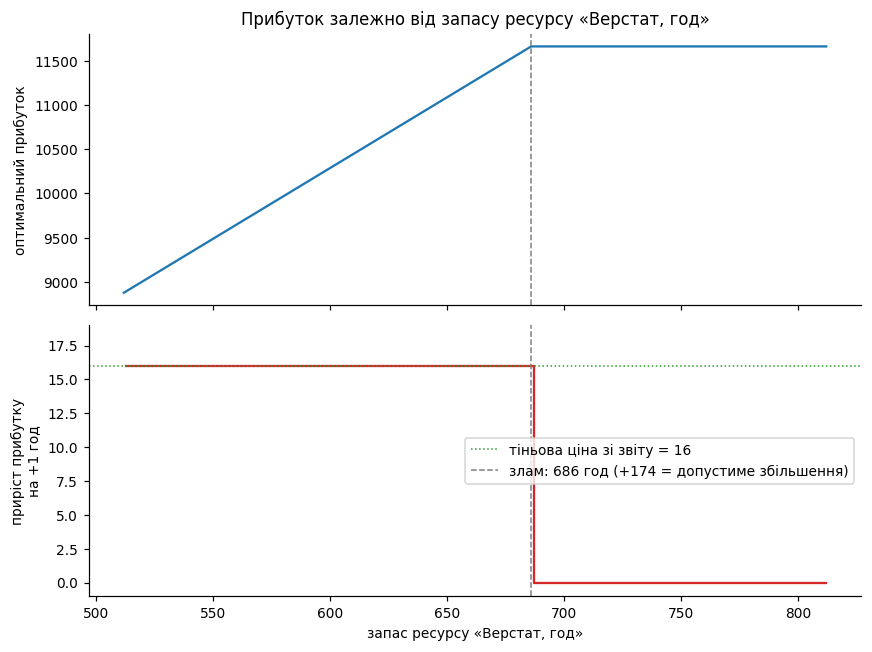

In [109]:
кроки = np.arange(0, 301)                       # додаткові години верстата: 0..300
прибутки = []
for d in кроки:
    bb = b.copy()
    bb[k] += d
    прибутки.append(розвязати_linprog(bb)[1])
прибутки = np.array(прибутки)
приріст = np.diff(прибутки)                     # приріст від кожної наступної години

межа = int(np.argmax(приріст < тіньові[k] - 1e-6))   # перша година, де нахил змінився
print('Нахил дорівнює тіньовій ціні %.0f для перших %d додаткових годин' % (тіньові[k], межа))
print('Запас, на якому стається злам: %d год (база %d + %d)' % (b[k] + межа, b[k], межа))
print('Нахил після зламу: %.2f' % (round(приріст[межа], 6) + 0.0))

запас_осі = b[k] + кроки
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
ax1.plot(запас_осі, прибутки, color='tab:blue')
ax1.axvline(b[k] + межа, color='grey', ls='--', lw=1)
ax1.set_ylabel('оптимальний прибуток')
ax1.set_title('Прибуток залежно від запасу ресурсу «%s»' % ресурси[k])
ax2.step(запас_осі[1:], приріст, where='post', color='tab:red')
ax2.axhline(тіньові[k], color='tab:green', ls=':', lw=1, label='тіньова ціна зі звіту = %.0f' % тіньові[k])
ax2.axvline(b[k] + межа, color='grey', ls='--', lw=1,
            label='злам: %d год (+%d = допустиме збільшення)' % (b[k] + межа, межа))
ax2.set_ylabel('приріст прибутку\nна +1 год')
ax2.set_xlabel('запас ресурсу «%s»' % ресурси[k])
ax2.set_ylim(-1, тіньові[k] + 3)
ax2.legend(loc='center right')
plt.tight_layout()
plt.show()

**Відповідь 5.2:** перші **174** додаткові години кожна дає рівно +16 — на нижньому графіку це рівна
лінія. Після 686 год (512 + 174) приріст падає до **0**, прибуток зупиняється на 11 662. Це те саме
число, що «допустиме збільшення» 174 у звіті Excel.

Чому саме 174: коли годин верстата більше, вигідніше робити більше крісел і менше лав. На 686 год лав
уже 0, крісел 228,67, і тепер вся фанера йде на крісла ($3 \cdot 228{,}67 = 686$). Далі заважає вже
фанера, а не верстат, тому зайві години нічого не дають. Отже, тіньова ціна правдива тільки в
межах діапазону зі звіту.

---
# Етап 6. Рішення про закупівлю

Постачальник пропонує вам додатковий обсяг ресурсу — див. блок «ПРОПОЗИЦІЯ
ПОСТАЧАЛЬНИКА» у ваших даних.

### Завдання 6.1
Дайте відповідь директорові на три питання, спираючись на числа, а не на здоровий глузд:

1. **Брати чи не брати?** Порівняйте ціну пропозиції з тіньовою ціною.
2. **Скільки саме брати?** Постачальник пропонує більше, ніж вам потрібно.
3. **Скільки на цьому заробимо?** Порахуйте виграш і перевірте його прямим
   розв'язанням задачі з новим запасом.

Пропозиція: Верстат, год, ціна 11.3, до 348 од.
Тіньова ціна цього ресурсу: 16.00 -> БРАТИ

Найвигідніший обсяг закупівлі: 174 од.
Прогноз за звітом: (16 - 11.3) * 174 = 817.80

        прибуток  чистий виграш
купити                         
0         8878.0            0.0
1         8894.0            4.7
100      10478.0          470.0
173      11646.0          813.1
174      11662.0          817.8
175      11662.0          806.5
250      11662.0          -41.0
348      11662.0        -1148.4

Пряма перевірка (PuLP), запас Верстат, год = 686:
  план: [228.667   0.      0.      0.   ] | прибуток 11662.00 (було 8878.00)
  приріст прибутку 2784.00 - витрати 1966.20 = чистий виграш 817.80
  якщо взяти весь обсяг 348: чистий результат -1148.40


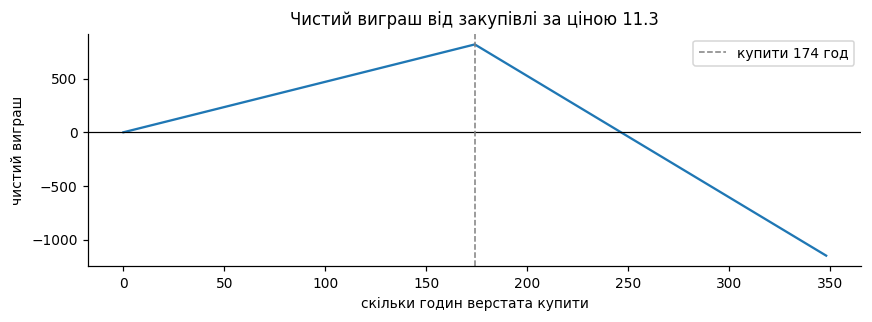

In [110]:
р = V['ресурс_пропозиції']
ціна, обсяг = V['ціна_пропозиції'], V['обсяг_пропозиції']
ДОПУСТИМЕ_ЗБІЛЬШЕННЯ = 174          # зі звіту Excel для цього ресурсу
print('Пропозиція: %s, ціна %.1f, до %d од.' % (ресурси[р], ціна, обсяг))
print('Тіньова ціна цього ресурсу: %.2f -> %s' % (
    тіньові[р], 'БРАТИ' if тіньові[р] > ціна else 'НЕ БРАТИ'))
print()

# прибуток мінус витрати на закупівлю для кожного можливого обсягу
рядки = []
for q in range(0, обсяг + 1):
    bb = b.copy()
    bb[р] += q
    п = розвязати_linprog(bb)[1]
    рядки.append((q, п, п - ціна * q - прибуток))
тбл = pd.DataFrame(рядки, columns=['купити', 'прибуток', 'чистий виграш']).set_index('купити')

q_опт = int(тбл['чистий виграш'].idxmax())
print('Найвигідніший обсяг закупівлі: %d од.' % q_опт)
print('Прогноз за звітом: (%.0f - %.1f) * %d = %.2f'
      % (тіньові[р], ціна, ДОПУСТИМЕ_ЗБІЛЬШЕННЯ, (тіньові[р] - ціна) * ДОПУСТИМЕ_ЗБІЛЬШЕННЯ))
print()
print(тбл.loc[[0, 1, 100, 173, 174, 175, 250, обсяг]].round(2).to_string())

# пряма перевірка: нова задача з запасом 512 + 174
bb = b.copy()
bb[р] += q_опт
план_нов, прибуток_нов, тіньові_нов = розвязати_pulp(bb)
print()
print('Пряма перевірка (PuLP), запас %s = %d:' % (ресурси[р], bb[р]))
print('  план:', план_нов.round(3), '| прибуток %.2f (було %.2f)' % (прибуток_нов, прибуток))
print('  приріст прибутку %.2f - витрати %.2f = чистий виграш %.2f'
      % (прибуток_нов - прибуток, ціна * q_опт, прибуток_нов - прибуток - ціна * q_опт))
print('  якщо взяти весь обсяг %d: чистий результат %.2f' % (обсяг, тбл.loc[обсяг, 'чистий виграш']))

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(тбл.index, тбл['чистий виграш'], color='tab:blue')
ax.axhline(0, color='black', lw=0.8)
ax.axvline(q_опт, color='grey', ls='--', lw=1, label='купити %d год' % q_опт)
ax.set_xlabel('скільки годин верстата купити')
ax.set_ylabel('чистий виграш')
ax.set_title('Чистий виграш від закупівлі за ціною %.1f' % ціна)
ax.legend()
plt.tight_layout()
plt.show()

**Відповідь 6.1:** постачальник пропонує **години верстата** по **11,3**, до **348** год.

* **Брати чи ні і чому:** **брати.** Година верстата приносить 16 (тіньова ціна), а коштує 11,3 —
  з кожної години 4,7 чистими.
* **Скільки одиниць має сенс купити і чому не більше:** **174 год.** Саме стільки діє тіньова ціна 16
  (етап 5). Після цього верстат уже не обмежує, години перестають давати прибуток, і ми просто
  платили б по 11,3 ні за що.
* **Очікуваний виграш:** $(16 - 11{,}3) \cdot 174 = $ **817,80**.
* **Перевірка прямим розв'язанням дала:** з запасом 686 год прибуток **11 662** замість 8 878, тобто
  +2 784; мінус оплата $174 \cdot 11{,}3 = 1\,966{,}20$ — виходить **817,80**, як і рахувала. Якби
  взяла всі 348 год, було б **−1 148,40**, тобто збиток.

---
# Етап 7. Перевірка розв'язку

### Завдання 7.1
Порахуйте дві величини:

* скільки виробів мають **ненульовий** випуск;
* скільки обмежень **зв'язні** (ресурс витрачено повністю).

Порівняйте.

In [111]:
ДОПУСК = 1e-6
залишки = b - A @ план
ненульових = int(np.sum(план > ДОПУСК))
звязних = int(np.sum(np.abs(залишки) < ДОПУСК))

print(pd.DataFrame({'використано': (A @ план).round(3), 'запас': b,
                    'залишок': залишки.round(3),
                    'зв’язне': np.abs(залишки) < ДОПУСК}, index=ресурси).to_string())
print()
print('ненульові вироби:', [вироби[j] for j in range(len(вироби)) if план[j] > ДОПУСК])

                   використано   запас   залишок  зв’язне
Дубовий брус, м       1004.133  1189.0   184.867    False
Фанера, м²             686.000   686.0     0.000     True
Фурнітура, компл.      159.067  1311.0  1151.933    False
Верстат, год           512.000   512.0     0.000     True
Лакування, год         775.467  1030.0   254.533    False

ненульові вироби: ['Крісло', 'Лава']


In [112]:
assert ненульових is not None and звязних is not None, 'спершу порахуйте'
print('ненульових змінних: %s | зв’язних обмежень: %s' % (ненульових, звязних))
assert ненульових == звязних, ('числа не збіглися — це сигнал. Перевірте розв’язок '
                               'і поясніть причину в клітинці нижче')
print('Етап 7 пройдено')

ненульових змінних: 2 | зв’язних обмежень: 2
Етап 7 пройдено


**Відповідь 7.1:** **2 = 2**, збіглося. Виробляються крісло і лава, повністю витрачені фанера і
верстат.

Так і має бути: оптимум у вершині, і дві ненульові змінні знаходяться саме з двох рівнянь для
вичерпаних ресурсів: $3x_1 + 6x_4 = 686$ і $3x_1 + x_4 = 512$, звідки $x_4 = 34{,}8$, $x_1 = 159{,}07$.

Якби числа не збіглися:

* **зв'язних більше** — розв'язок вироджений, тіньові ціни можуть бути неоднозначні, і звіту
  довіряти треба обережно (так буде на 686 год верстата: лава = 0, а верстат ще вичерпаний);
* **ненульових більше** — або є кілька однаково добрих планів, або десь помилка: не те обмеження,
  розв'язувач не дорахував, неправильний допуск при порівнянні.

---
# Етап 8. Цілочисельність

Ваш оптимальний план містить дробові числа. Виготовити 63,3 виробу неможливо.

### Завдання 8.1
Порівняйте три варіанти:

1. розв'язок без умови цілочисельності (уже маєте);
2. **округлений** план — округліть кожне значення до цілого й перевірте, чи він
   узагалі допустимий і скільки прибутку дає;
3. справжній **цілочисельний** оптимум — розв'яжіть задачу з умовою, що всі змінні цілі
   (`cat='Integer'` у PuLP або `integrality=1` у `linprog`).

In [113]:
def перевірити(план_x):
    перевищення = A @ план_x - b
    return bool(np.all(перевищення <= 1e-9)), перевищення

# 1) без цілочисельності
# 2) округлений до найближчого цілого
план_окр = np.round(план)
# 2а) для порівняння — округлений вниз (завжди допустимий для задачі з «≤» і A ≥ 0)
план_вниз = np.floor(план + 1e-9)
# 3) справжній цілочисельний оптимум
план_цілий, прибуток_цілий, _ = розвязати_pulp(b, цілі=True)

рядки = []
for назва, x_ in [('без умови цілочисельності', план), ('округлений', план_окр),
                  ('округлений вниз', план_вниз), ('цілочисельний оптимум', план_цілий)]:
    ок, перев = перевірити(x_)
    рядки.append([назва, np.round(x_, 3).tolist(), round(float(c @ x_), 2), 'так' if ок else 'НІ'])
    if not ок:
        for i in np.where(перев > 1e-9)[0]:
            print('%s: ресурс «%s» перевищено на %.0f (потрібно %.0f, є %.0f)'
                  % (назва, ресурси[i], перев[i], (A @ x_)[i], b[i]))
print()
print(pd.DataFrame(рядки, columns=['варіант', 'план', 'прибуток', 'допустимий?']).to_string(index=False))

округлений: ресурс «Фанера, м²» перевищено на 1 (потрібно 687, є 686)

                  варіант                      план  прибуток допустимий?
без умови цілочисельності [159.067, 0.0, 0.0, 34.8]    8878.0         так
               округлений   [159.0, 0.0, 0.0, 35.0]    8879.0          НІ
          округлений вниз   [159.0, 0.0, 0.0, 34.0]    8857.0         так
    цілочисельний оптимум   [159.0, 1.0, 0.0, 34.0]    8873.0         так


**Відповідь 8.1:**

| Варіант | План (крісло, стілець, табурет, лава) | Прибуток | Допустимий? |
|---|---|---|---|
| без умови цілочисельності | (159,07; 0; 0; 34,8) | 8 878 | так |
| округлений | (159; 0; 0; 35) | 8 879 | **ні** — фанери треба 687 м², а є 686 |
| *округлений вниз (для порівняння)* | (159; 0; 0; 34) | 8 857 | так |
| цілочисельний оптимум | (159; **1**; 0; 34) | **8 873** | так |

**Висновок:** округлювати не можна, і в мене це видно одразу.

Звичайне округлення дає 35 лав, а на них не вистачає 1 м² фанери — такий план зробити неможливо.
До того ж його прибуток 8 879 більший за оптимум 8 878, чого для реального плану бути не може.

Цілочисельний оптимум взагалі не отримати округленням: у ньому з'являється 1 стілець, якого не було
в дробовому плані. Після (159; 0; 0; 34) лишається 1 год верстата і 5 м² фанери — на крісло чи лаву
не вистачає, а на стілець (1 год і 4 м²) якраз. Округлення вниз працює, але дає на 16 менше.

Тут різниця маленька, бо виробів багато. Якби план був на кілька штук, помилка від округлення була б
набагато помітніша, тому краще одразу ставити `cat='Integer'`.

---
# ЧАСТИНА 2. Транспортна задача

Друга частина виконується самостійно. Тут ви застосуєте ту саму методику до задачі
іншого класу — і побачите, що вона поводиться інакше.

# Етап 9. Ваші дані

### Завдання 9.1
Сформуйте власні дані:

* **три міста-постачальники** — за першими трьома літерами вашого **прізвища**;
* **чотири міста-споживачі** — за першими чотирма літерами вашого **імені**;
* **матриця відстаней 3 × 4** — реальні відстані автошляхами за Google Maps, у кілометрах;
* **запаси і попит** — невеликі цілі числа, підберіть так, щоб **сумарний запас
  дорівнював сумарному попиту**.

> Якщо на якусь літеру міста немає — беріть наступну літеру прізвища чи імені.
> Якщо сумарний запас не дорівнює попиту, задача з обмеженнями-рівностями
> **не матиме розв'язку взагалі**. Це не помилка Python — це властивість моделі.

In [ ]:
# Прізвище БОБринок -> Б, О, Б;  ім'я АНГЕліна -> А, Н, Г, Е.
# Єдине місто України на «Е» — Енергодар — тимчасово окуповане, реального маршруту
# автошляхами туди немає, тож за правилом беру наступну літеру імені — «Л» (Луцьк).
постачальники = ['Біла Церква', 'Одеса', 'Бердичів']
споживачі     = ['Ахтирка', 'Ніжин', 'Гайсин', 'Луцьк']
D = np.array([                                   # відстані автошляхами, км
    [467, 236, 193, 416],                        # Біла Церква
    [661, 625, 330, 811],                        # Одеса
    [570, 336, 181, 308],                        # Бердичів
], float)
запас = [24, 19, 32]                             # 75 од.
попит = [17, 13, 28, 17]                         # 75 од.

assert len(постачальники) == 3 and len(споживачі) == 4, 'потрібно 3 постачальники і 4 споживачі'
assert D.shape == (3, 4), 'матриця відстаней має бути 3 x 4'
assert sum(запас) == sum(попит), 'сумарний запас має дорівнювати сумарному попиту'
pd.DataFrame(D, index=постачальники, columns=споживачі)

,Ахтирка,Ніжин,Гайсин,Луцьк
Біла Церква,467.0,236.0,193.0,416.0
Одеса,661.0,625.0,330.0,811.0
Бердичів,570.0,336.0,181.0,308.0


---
# Етап 10. Розв'язання транспортної задачі

### Завдання 10.1
Розв'яжіть задачу **двічі різними засобами**: наприклад `pulp` і
`scipy.optimize.linprog(method='highs')`. Обмеження — рівності.

Для кожного розв'язку виведіть: оптимальний план перевезень, сумарну вартість
і **тіньові ціни всіх обмежень**.

In [115]:
# ---- розв'язок 1: PuLP -------------------------------------------------------
m, n = D.shape
тз = pulp.LpProblem('транспортна', pulp.LpMinimize)
X = [[pulp.LpVariable('x_%d_%d' % (i, j), lowBound=0) for j in range(n)] for i in range(m)]
тз += pulp.lpSum(D[i, j] * X[i][j] for i in range(m) for j in range(n))      # вартість, од.·км
for i in range(m):
    тз += pulp.lpSum(X[i][j] for j in range(n)) == запас[i], 'запас_%d' % i
for j in range(n):
    тз += pulp.lpSum(X[i][j] for i in range(m)) == попит[j], 'попит_%d' % j
тз.solve(pulp.PULP_CBC_CMD(msg=0))
assert pulp.LpStatus[тз.status] == 'Optimal'

план_т1 = np.array([[X[i][j].value() for j in range(n)] for i in range(m)])
вартість_1 = pulp.value(тз.objective)
u1 = np.array([тз.constraints['запас_%d' % i].pi for i in range(m)])
v1 = np.array([тз.constraints['попит_%d' % j].pi for j in range(n)])

print('PuLP — сумарна вартість: %.0f' % вартість_1)
display(pd.DataFrame(план_т1, index=постачальники, columns=споживачі))
print('тіньові ціни постачальників u:', dict(zip(постачальники, u1)))
print('тіньові ціни споживачів     v:', dict(zip(споживачі, v1)))

PuLP — сумарна вартість: 24412


,Ахтирка,Ніжин,Гайсин,Луцьк
Біла Церква,11.0,13.0,0.0,0.0
Одеса,6.0,0.0,13.0,0.0
Бердичів,0.0,0.0,15.0,17.0


тіньові ціни постачальників u: {'Біла Церква': np.float64(236.0), 'Одеса': np.float64(430.0), 'Бердичів': np.float64(281.0)}
тіньові ціни споживачів     v: {'Ахтирка': np.float64(231.0), 'Ніжин': np.float64(0.0), 'Гайсин': np.float64(-100.0), 'Луцьк': np.float64(27.0)}


In [116]:
# ---- розв'язок 2: scipy.optimize.linprog --------------------------------------
# змінна x[i, j] має номер i*n + j
A_eq = np.zeros((m + n, m * n))
for i in range(m):
    A_eq[i, i * n:(i + 1) * n] = 1          # рядок постачальника i
for j in range(n):
    A_eq[m + j, j::n] = 1                    # стовпець споживача j
r_т = linprog(D.ravel(), A_eq=A_eq, b_eq=запас + попит,
              bounds=[(0, None)] * (m * n), method='highs')
assert r_т.status == 0, r_т.message

план_т2 = r_т.x.reshape(m, n)
вартість_2 = r_т.fun
u2, v2 = r_т.eqlin.marginals[:m], r_т.eqlin.marginals[m:]

print('linprog — сумарна вартість: %.0f' % вартість_2)
display(pd.DataFrame(план_т2, index=постачальники, columns=споживачі))
print('тіньові ціни постачальників u:', dict(zip(постачальники, u2)))
print('тіньові ціни споживачів     v:', dict(zip(споживачі, v2)))

linprog — сумарна вартість: 24412


,Ахтирка,Ніжин,Гайсин,Луцьк
Біла Церква,11.0,13.0,0.0,0.0
Одеса,6.0,0.0,13.0,0.0
Бердичів,0.0,0.0,15.0,17.0


тіньові ціни постачальників u: {'Біла Церква': np.float64(-0.0), 'Одеса': np.float64(194.0), 'Бердичів': np.float64(45.0)}
тіньові ціни споживачів     v: {'Ахтирка': np.float64(467.0), 'Ніжин': np.float64(236.0), 'Гайсин': np.float64(136.0), 'Луцьк': np.float64(263.0)}


### Завдання 10.2 — головне питання цієї частини
Порівняйте два набори тіньових цін.

**Сумарна вартість у двох розв'язувачів однакова. А тіньові ціни?**

Якщо вони різні — це не помилка. Знайдіть закономірність: подивіться на різницю
між відповідними значеннями окремо для постачальників і окремо для споживачів.

In [117]:
порівняння = pd.DataFrame({
    'PuLP': np.r_[u1, v1],
    'linprog': np.r_[u2, v2],
}, index=['запас: ' + s for s in постачальники] + ['попит: ' + s for s in споживачі])
порівняння['різниця PuLP − linprog'] = порівняння['PuLP'] - порівняння['linprog']
print('вартість: PuLP %.0f, linprog %.0f, плани однакові: %s'
      % (вартість_1, вартість_2, np.allclose(план_т1, план_т2)))
print()
print(порівняння.to_string())

# інваріант: сума u_i + v_j однакова в обох розв'язувачів
print()
print('u_i + v_j (PuLP):')
print(pd.DataFrame(u1[:, None] + v1[None, :], index=постачальники, columns=споживачі).to_string())
print('u_i + v_j (linprog):')
print(pd.DataFrame(u2[:, None] + v2[None, :], index=постачальники, columns=споживачі).to_string())
print()
print('двоїста оцінка Σ запас·u + Σ попит·v: PuLP %.0f, linprog %.0f'
      % (np.dot(запас, u1) + np.dot(попит, v1), np.dot(запас, u2) + np.dot(попит, v2)))

вартість: PuLP 24412, linprog 24412, плани однакові: True

                     PuLP  linprog  різниця PuLP − linprog
запас: Біла Церква  236.0     -0.0                   236.0
запас: Одеса        430.0    194.0                   236.0
запас: Бердичів     281.0     45.0                   236.0
попит: Ахтирка      231.0    467.0                  -236.0
попит: Ніжин          0.0    236.0                  -236.0
попит: Гайсин      -100.0    136.0                  -236.0
попит: Луцьк         27.0    263.0                  -236.0

u_i + v_j (PuLP):
             Ахтирка  Ніжин  Гайсин  Луцьк
Біла Церква    467.0  236.0   136.0  263.0
Одеса          661.0  430.0   330.0  457.0
Бердичів       512.0  281.0   181.0  308.0
u_i + v_j (linprog):
             Ахтирка  Ніжин  Гайсин  Луцьк
Біла Церква    467.0  236.0   136.0  263.0
Одеса          661.0  430.0   330.0  457.0
Бердичів       512.0  281.0   181.0  308.0

двоїста оцінка Σ запас·u + Σ попит·v: PuLP 24412, linprog 24412


**Відповідь 10.2:**

* **Вартість у двох розв'язувачів:** однакова, **24 412** од.·км, і план однаковий.
* **Тіньові ціни збіглися чи ні:** **ні.** PuLP: u = (236; 430; 281), v = (231; 0; −100; 27);
  linprog: u = (0; 194; 45), v = (467; 236; 136; 263).
* **Яку закономірність ви побачили в різниці:** у всіх постачальників різниця **+236**, у всіх
  споживачів **−236**. Тобто один набір — це інший, зсунутий на одне число: до $u$ додали $k$,
  від $v$ відняли $k$. Тому $u_i + v_j$ в обох однакові (для маршрутів з плану це просто відстань), і
  двоїста оцінка теж 24 412 в обох — бо запас і попит у сумі рівні, і $k$ скорочується.

  Чому так: одне з 7 обмежень зайве. Якщо скласти всі рівняння для запасів, вийде те саме, що сума
  рівнянь для попиту (обидва кажуть «усього 75»). Тому тіньові ціни визначені не однозначно, і
  кожна програма просто обирає свій варіант: linprog поставив 0 Білій Церкві, PuLP — Ніжину.
  **Правильні обидва.**
* **Що це означає для того, хто збирається ухвалювати рішення за цим звітом:** окрему тіньову ціну тут
  читати не можна. «Скільки коштує ще одна одиниця запасу в Одесі» — питання без змісту, бо без
  додаткового попиту баланс порушиться і задача не розв'яжеться. Сенс мають тільки пари: $u_i + v_j$ —
  скільки додасться до вартості, якщо збільшити запас у $i$ і попит у $j$ разом, та різниці між
  складами. Порівнювати тіньову ціну з ринковою, як на етапі 6, тут не вийде — у цьому і є межа
  методу з частини 1.

---
# Етап 11. Перевірка розв'язку — і чому вона тут не працює

### Завдання 11.1
Порахуйте для транспортної задачі те саме, що на етапі 7:

* кількість **ненульових перевезень**;
* кількість **зв'язних обмежень**.

Порівняйте з числом `3 + 4 = 7` — кількістю обмежень у задачі.

In [118]:
ненульових_т = int(np.sum(план_т1 > ДОПУСК))
нев_язки = np.r_[запас - план_т1.sum(axis=1), попит - план_т1.sum(axis=0)]
звязних_т = int(np.sum(np.abs(нев_язки) < ДОПУСК))
ранг = np.linalg.matrix_rank(A_eq)

print('ненульових перевезень:', ненульових_т)
print('зв’язних обмежень:    ', звязних_т, 'з', m + n)
print('ранг матриці обмежень:', ранг, '= m + n - 1 =', m + n - 1)
print('маршрути у плані:', [(постачальники[i], споживачі[j], план_т1[i, j])
                            for i in range(m) for j in range(n) if план_т1[i, j] > ДОПУСК])

ненульових перевезень: 6
зв’язних обмежень:     7 з 7
ранг матриці обмежень: 6 = m + n - 1 = 6
маршрути у плані: [('Біла Церква', 'Ахтирка', np.float64(11.0)), ('Біла Церква', 'Ніжин', np.float64(13.0)), ('Одеса', 'Ахтирка', np.float64(6.0)), ('Одеса', 'Гайсин', np.float64(13.0)), ('Бердичів', 'Гайсин', np.float64(15.0)), ('Бердичів', 'Луцьк', np.float64(17.0))]


**Відповідь 11.1:**

* **Ненульових перевезень:** **6** (Біла Церква → Ахтирка 11, → Ніжин 13; Одеса → Ахтирка 6,
  → Гайсин 13; Бердичів → Гайсин 15, → Луцьк 17).
* **Зв'язних обмежень:** **7 з 7.**
* **Чому в транспортній задачі зв'язними виявляються всі обмеження:** бо це рівності. Залишку бути не
  може: склад вивозить усе, місто отримує рівно скільки треба. Так у будь-якому допустимому плані,
  тому тут «зв'язне» не означає «дефіцитне».
* **На скільки ненульових перевезень менше і чому саме на стільки:** на **одне**: 6 = 3 + 4 − 1. Незалежних
  рівнянь лише 6 (одне зайве, як на етапі 10, ранг = 6), отже і базисних змінних 6. Тому перевірка з
  етапу 7 тут не підходить — для транспортної задачі має бути «ненульових = m + n − 1».

  Якщо ненульових було б ще менше, план вироджений. Таке буває, коли якась сума запасів дорівнює
  сумі попиту (наприклад, 20 і 20), тому я підібрала числа без таких збігів.

### Завдання 11.2 — візуалізація
Побудуйте дві теплові карти поруч: матрицю відстаней і матрицю оптимальних перевезень.
Підпишіть осі та значення в комірках.

*За бажанням (не оцінюється): граф маршрутів через `networkx`, де товщина ребра
пропорційна обсягу перевезення.*

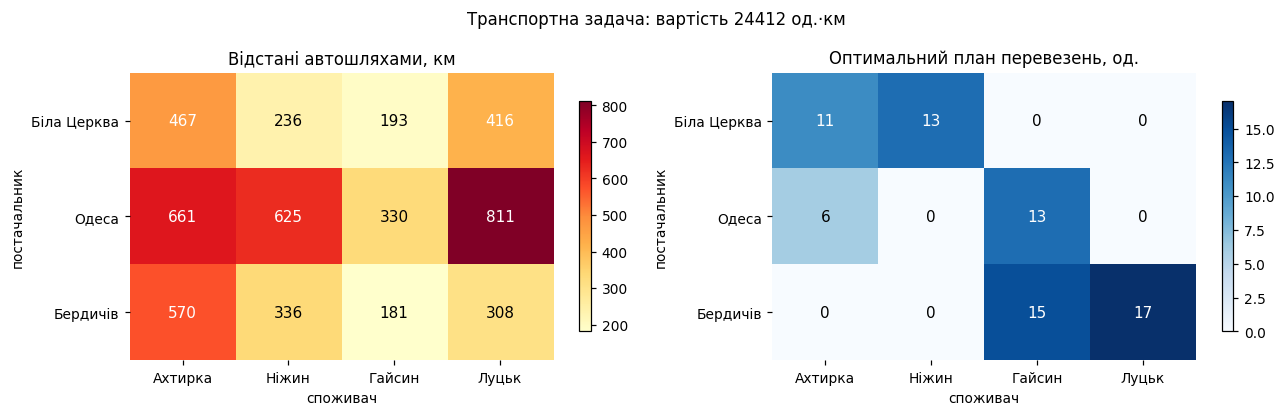

In [119]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, M, назва, cmap, fmt in [
        (axes[0], D, 'Відстані автошляхами, км', 'YlOrRd', '%.0f'),
        (axes[1], план_т1, 'Оптимальний план перевезень, од.', 'Blues', '%.0f')]:
    im = ax.imshow(M, cmap=cmap, aspect='auto')
    ax.set_xticks(range(n), споживачі)
    ax.set_yticks(range(m), постачальники)
    ax.set_xlabel('споживач')
    ax.set_ylabel('постачальник')
    ax.set_title(назва)
    поріг = M.max() / 2
    for i in range(m):
        for j in range(n):
            ax.text(j, i, fmt % M[i, j], ha='center', va='center',
                    color='white' if M[i, j] > поріг else 'black', fontsize=10)
    ax.spines[:].set_visible(False)
    fig.colorbar(im, ax=ax, shrink=0.8)
fig.suptitle('Транспортна задача: вартість %.0f од.·км' % вартість_1)
plt.tight_layout()
plt.show()

**Висновок:** здебільшого везуть найкоротшими маршрутами (Бердичів → Гайсин 181 км, Біла Церква →
Ніжин 236 км, Бердичів → Луцьк 308 км). Але Одеса далеко від усіх, і її товар іде в Гайсин і навіть в
Ахтирку (661 км), щоб ближчі склади обслужили інші міста — мінімізується загальна вартість, а не
кожен маршрут окремо.

---
# Етап 12. Декларація про використання інструментів штучного інтелекту

Користуватися мовними моделями **дозволено**. Обов'язковою є прозорість.
Порушенням є не використання інструмента, а нездатність пояснити власний код
і власні числа на захисті.

Для кожного етапу оберіть одне: `'ні'`, `'синтаксис'`, `'код, перевірено'`,
`'текст, перероблено'`, `'текст, як є'`.

In [120]:
ІНСТРУМЕНТИ_ШІ = 'Claude'

ДЕКЛАРАЦІЯ = {
    'етап 1, формалізація моделі':          'текст, як є',
    'етап 2, побудова моделі в Excel':      'код, перевірено',
    'етап 3, код на Python':                'код, перевірено',
    'етапи 4–5, читання та перевірка звіту': 'текст, як є',
    'етап 6, рішення про закупівлю':        'текст, як є',
    'етапи 7–8, перевірка та цілочисельність': 'код, перевірено',
    'етапи 9–11, транспортна задача':       'код, перевірено',
}

# Що саме ви перевірили за згенерованим кодом чи текстом — конкретно.
ЩО_ПЕРЕВІРЕНО = ('Звірила оптимальний план і прибуток 8878 у трьох джерелах: Excel Solver, PuLP і '
                 'linprog. Тіньову ціну верстата 16 перевірила, додавши 1 годину (+16), а межу 174 '
                 'знайшла перебором запасу на графіку. Виграш від закупівлі 817,8 перевірила '
                 'прямим розв’язанням із запасом 686. Округлений план перевірила на ресурсах: '
                 'фанери не вистачає. У транспортній задачі звірила вартість 24412 у двох '
                 'розв’язувачах і переконалася, що тіньові ціни відрізняються на сталу 236.')

# True означає: я можу пояснити кожен рядок свого коду, відтворити будь-яке число
# цієї роботи та внести зміни в модель на вимогу під час захисту.
ПІДТВЕРДЖУЮ = True

In [121]:
# --- перевірка повноти декларації: клітинку не редагувати --------------------
ДОЗВОЛЕНІ = {'ні', 'синтаксис', 'код, перевірено', 'текст, перероблено', 'текст, як є'}
assert ІНСТРУМЕНТИ_ШІ.strip(), 'Вкажіть інструменти або напишіть «не використовував»'
порожні = [k for k, v in ДЕКЛАРАЦІЯ.items() if not str(v).strip()]
assert not порожні, 'Не заповнено: %s' % '; '.join(порожні)
чужі = {v for v in ДЕКЛАРАЦІЯ.values() if v not in ДОЗВОЛЕНІ}
assert not чужі, 'Недопустимі значення: %s' % ', '.join(sorted(чужі))
assert len(ЩО_ПЕРЕВІРЕНО.strip()) >= 120, ('Опишіть конкретніше (зараз %d символів, '
                                           'потрібно щонайменше 120)' % len(ЩО_ПЕРЕВІРЕНО.strip()))
assert ПІДТВЕРДЖУЮ is True, 'Підтвердьте, що можете пояснити власний код на захисті'
print('ДЕКЛАРАЦІЯ ПРО ВИКОРИСТАННЯ ІНСТРУМЕНТІВ ШІ')
print('=' * 78)
print('%-42s %s' % ('автор:', ПІБ))
print('%-42s %s' % ('інструменти:', ІНСТРУМЕНТИ_ШІ))
print('-' * 78)
for k, v in ДЕКЛАРАЦІЯ.items():
    print('%-42s %s' % (k + ':', v))
print('-' * 78)
print(ЩО_ПЕРЕВІРЕНО)

ДЕКЛАРАЦІЯ ПРО ВИКОРИСТАННЯ ІНСТРУМЕНТІВ ШІ
автор:                                     Бобринок Ангеліна Вадимівна
інструменти:                               Claude
------------------------------------------------------------------------------
етап 1, формалізація моделі:               текст, як є
етап 2, побудова моделі в Excel:           код, перевірено
етап 3, код на Python:                     код, перевірено
етапи 4–5, читання та перевірка звіту:     текст, як є
етап 6, рішення про закупівлю:             текст, як є
етапи 7–8, перевірка та цілочисельність:   код, перевірено
етапи 9–11, транспортна задача:            код, перевірено
------------------------------------------------------------------------------
Звірила оптимальний план і прибуток 8878 у трьох джерелах: Excel Solver, PuLP і linprog. Тіньову ціну верстата 16 перевірила, додавши 1 годину (+16), а межу 174 знайшла перебором запасу на графіку. Виграш від закупівлі 817,8 перевірила прямим розв’язанням із запасом 686. Окру

---
# Крок 13. Фінальна самоперевірка

In [122]:
перевірки = {
    'ПІБ і варіант заповнено':            bool(ПІБ) and 1 <= ВАРІАНТ <= 30,
    'Excel і Python дали однаковий план': abs(прибуток - EXCEL_ПРИБУТОК) < 0.5,
    'перевірку «ненульові = зв’язні» зроблено': ненульових == звязних,
    'дані транспортної задачі введено':   len(постачальники) == 3 and len(споживачі) == 4,
    'баланс запасів і попиту':            sum(запас) == sum(попит),
    'декларацію заповнено':               bool(ІНСТРУМЕНТИ_ШІ.strip()) and ПІДТВЕРДЖУЮ is True,
}
for k, v in перевірки.items():
    print(('OK   ' if v else 'НЕ ОК') + '  ' + k)


OK     ПІБ і варіант заповнено
OK     Excel і Python дали однаковий план
OK     перевірку «ненульові = зв’язні» зроблено
OK     дані транспортної задачі введено
OK     баланс запасів і попиту
OK     декларацію заповнено
